# Final four-model evaluation and reproducibility

This CPU-only notebook evaluates exactly **DDPM-U32**, **DDPM-C32**, **DDPM-U64**, and **DDPM-C64** from saved evidence. It never trains, samples, or reruns an evaluator. The questions are distributional quality/diversity, conditional adherence, efficiency, and the limits of supported comparisons.

## 1. Public family and frozen contracts

| Native resolution / updates | Unconditional | Conditional |
|---|---|---|
| 32 px / 40k | DDPM-U32 | DDPM-C32 |
| 64 px / 60k | DDPM-U64 | DDPM-C64 |

Conditional models add text encoding with CA8+CA16; unconditional models receive no caption. Architecture, resolution, update budget, preprocessing and independently trained trajectories are confounders. Common-32 KID uses its named standardization route; FID is exploratory. Conditional LPIPS is native within-prompt/across-seed diversity, while unconditional LPIPS is marginal diversity: they are not one ranking. MAA tests individual attributes, EAM all four attributes, and MacroPSR the defining withheld OOD pair; these are evaluator predictions, not human judgments.

In [18]:
from __future__ import annotations
import hashlib, json
from pathlib import Path
import matplotlib.pyplot as plt
ROOT=Path.cwd().resolve()
while not (ROOT/'pyproject.toml').is_file() and ROOT.parent!=ROOT: ROOT=ROOT.parent
FIGURE_DIR=ROOT/'docs/report/figures'; FIGURE_DIR.mkdir(parents=True,exist_ok=True)
paths={
 'manifest':ROOT/'src/tiny_avatar_diffusion/public_model_manifest.json',
 'step9b':ROOT/'results/runs/v2a_step9b_final_supplementary_ema60k_v1/five_endpoint_comparison.json',
 'step13':ROOT/'results/runs/step13_final_unconditional_benchmark_v1/summary.json',
 'dr04':ROOT/'results/runs/dr04_final_conditioning_v1/final_conditioning_summary.json',
 'dr05_quality':ROOT/'results/runs/dr05_final_quality_v1/final_quality_summary.json',
 'dr05_diversity':ROOT/'results/runs/dr05_final_diversity_v1/diversity_summary.json'}
assert all(p.is_file() for p in paths.values())
manifest=json.loads(paths['manifest'].read_text()); step9b=json.loads(paths['step9b'].read_text()); step13=json.loads(paths['step13'].read_text()); dr04=json.loads(paths['dr04'].read_text()); dr05_quality=json.loads(paths['dr05_quality'].read_text()); dr05_diversity=json.loads(paths['dr05_diversity'].read_text())
public={m['id']:m for m in manifest['models']}
assert set(public)=={'DDPM-U32','DDPM-C32','DDPM-U64','DDPM-C64'} and step13['status']=='COMPLETE' and dr04['FINAL_SCIENTIFIC_EVALUATION']
print('Loaded public manifest and authenticated frozen records.')

Loaded public manifest and authenticated frozen records.


## 2. Provenance boundary

STEP 13 is the final U32/U64 source (400 samples, Common-32 pool of 808 real images, 200 disjoint marginal-LPIPS pairs). STEP 9B is the matched supplementary C32/C64 source. DR04 is a separate historical 20k conditioning record: its generator checkpoint, evaluator, prompt pool, input route and aggregation do not match the released C32/C64 comparison, so it is provenance only and is not plotted as a final-model result. DR05 records likewise bind historical 20k packages.

For unconditional models MAA, EAM and MacroPSR are not applicable, not zero or missing.

In [19]:
for name in ('DDPM-U32','DDPM-C32','DDPM-U64','DDPM-C64'):
 m=public[name]; p=ROOT/m['checkpoint']; assert p.is_file() and len(m['sha256'])==64
 print(f"{name}: {m['resolution']}px, EMA, {m['parameters']:,} parameters, checkpoint present")
VERIFY_CHECKPOINT_SHA256=False
if VERIFY_CHECKPOINT_SHA256:
 for name,m in public.items(): assert hashlib.sha256((ROOT/m['checkpoint']).read_bytes()).hexdigest()==m['sha256']
 print('All four public checkpoint hashes match.')
else: print('Set VERIFY_CHECKPOINT_SHA256=True to recompute four file hashes; default does not read large weights.')
by={r['endpoint']:r for r in step9b}; c32=by['h7_ca8_ca16']; c64=by['v2_a_ema60k_supplementary']; u32=step13['endpoints']['v1_40k']['metrics']; u64=step13['endpoints']['v2a_60k']['metrics']

DDPM-U32: 32px, EMA, 4,595,779 parameters, checkpoint present
DDPM-C32: 32px, EMA, 4,749,059 parameters, checkpoint present
DDPM-U64: 64px, EMA, 5,077,123 parameters, checkpoint present
DDPM-C64: 64px, EMA, 5,230,403 parameters, checkpoint present
Set VERIFY_CHECKPOINT_SHA256=True to recompute four file hashes; default does not read large weights.


## 3. Conditional generation: adherence, quality and diversity

The figure below compares C32 and C64 only under their common STEP 9B supplementary OOD contract: the sealed 80-prompt, five-seed panel, dual-view evaluator, EMA weights and ancestral 1,000-step sampler. DR04 is deliberately excluded: it uses the 20k conditional checkpoint SHA `a1abad…`, a different evaluator SHA `414d…`, a 252-prompt / 1,260-slot plan with seeds 2026–2030, and its own panel/preprocessing/aggregation contract. A higher MAA need not yield high EAM or MacroPSR because joint success is stricter.

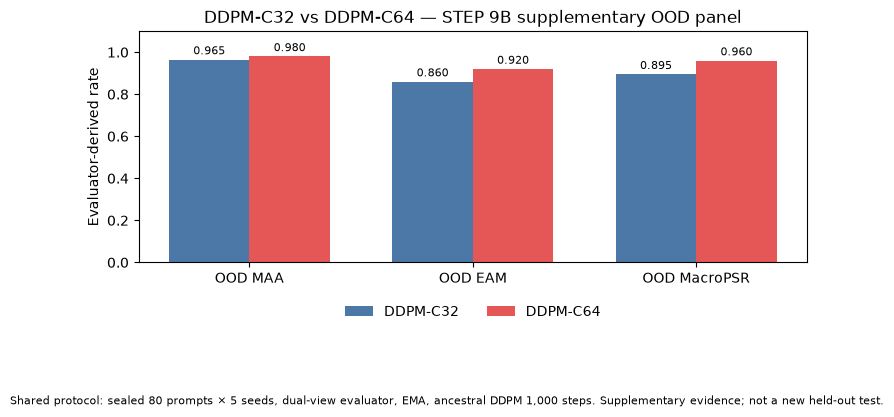

In [20]:
fig,ax=plt.subplots(figsize=(7.5,4.5)); x=range(3); w=.36
for off,label,row,color in [(-w/2,'DDPM-C32',c32,'#4c78a8'),(w/2,'DDPM-C64',c64,'#e45756')]:
 vv=[row[k] for k in ('maa_ood','eam_ood','macro_psr_ood')]; bars=ax.bar([z+off for z in x],vv,w,label=label,color=color)
 for q,v in zip(bars,vv): ax.text(q.get_x()+q.get_width()/2,v+.025,f'{v:.3f}',ha='center',fontsize=8)
ax.set(xticks=list(x),xticklabels=['OOD MAA','OOD EAM','OOD MacroPSR'],ylim=(0,1.10),ylabel='Evaluator-derived rate',title='DDPM-C32 vs DDPM-C64 — STEP 9B supplementary OOD panel'); ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.13),ncol=2)
fig.text(.5,.01,'Shared protocol: sealed 80 prompts × 5 seeds, dual-view evaluator, EMA, ancestral DDPM 1,000 steps. Supplementary evidence; not a new held-out test.',ha='center',fontsize=8); fig.tight_layout(rect=(0,.12,1,.92))
for e in ('png','pdf'): fig.savefig(FIGURE_DIR/f'final_conditional_adherence.{e}',dpi=300,bbox_inches='tight')
plt.show()

C:\Users\Bartolo\AppData\Local\Temp\ipykernel_26188\2699805672.py:6: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.suptitle('Final distributional quality: frozen endpoint records'); fig.text(.5,.01,'U32/U64: STEP 13; C32/C64: STEP 9B. Protocol boundaries are retained; FID is exploratory.',ha='center',fontsize=8); fig.tight_layout(rect=(0,.07,1,.90))


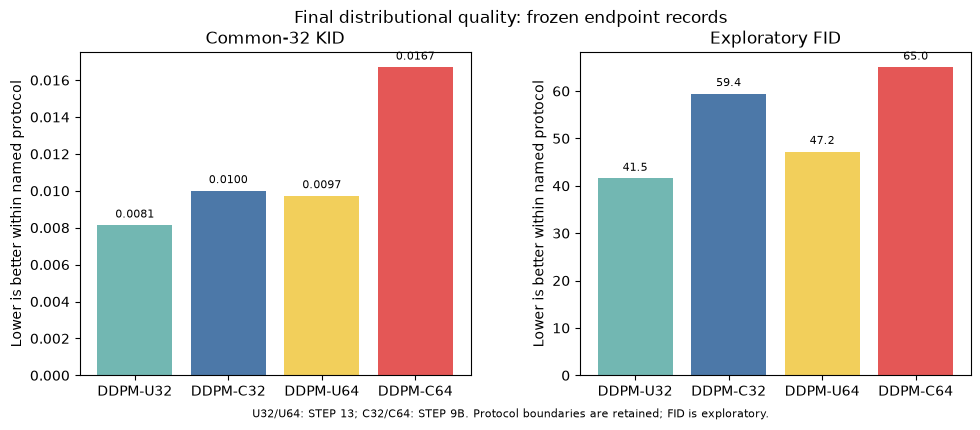

In [21]:
rows=[('DDPM-U32',u32['quality']['kid_common32'],u32['quality']['fid_common32_exploratory'],'#72b7b2'),('DDPM-C32',c32['kid_common32'],c32['fid_common32'],'#4c78a8'),('DDPM-U64',u64['quality']['kid_common32'],u64['quality']['fid_common32_exploratory'],'#f2cf5b'),('DDPM-C64',c64['kid_common32'],c64['fid_common32'],'#e45756')]
fig,ax=plt.subplots(1,2,figsize=(11.5,4.2),gridspec_kw={'wspace':.28})
for a,i,title,fmt in [(ax[0],1,'Common-32 KID','.4f'),(ax[1],2,'Exploratory FID','.1f')]:
 vals=[r[i] for r in rows]; bars=a.bar([r[0] for r in rows],vals,color=[r[3] for r in rows]); a.set(title=title,ylabel='Lower is better within named protocol'); a.tick_params(axis='x',rotation=0)
 for q,v in zip(bars,vals): a.text(q.get_x()+q.get_width()/2,v+max(vals)*.025,format(v,fmt),ha='center',fontsize=8)
fig.suptitle('Final distributional quality: frozen endpoint records'); fig.text(.5,.01,'U32/U64: STEP 13; C32/C64: STEP 9B. Protocol boundaries are retained; FID is exploratory.',ha='center',fontsize=8); fig.tight_layout(rect=(0,.07,1,.90))
for e in ('png','pdf'): fig.savefig(FIGURE_DIR/f'final_distributional_quality.{e}',dpi=300,bbox_inches='tight')
plt.show()

## 4. Efficiency, qualitative evidence, and conclusions

Final records report single-image ancestral-DDPM 1,000-step measurements on an RTX 4060 Laptop GPU: U32 **6.150 s / 29.3 MiB**, C32 **9.124 s / 29.9 MiB**, U64 **8.013 s / 36.1 MiB**, C64 **9.185 s / 36.7 MiB** (median latency / peak allocated CUDA memory). Allocated memory is not total VRAM use; source repetition schemes differ, so this is descriptive rather than a hardware ranking.

No authenticated, matched four-final-model gallery exists in the frozen records. Notebook 03 remains the conditional OOD qualitative source; it must not be relabelled as an unconditional comparison. Optional qualitative inference belongs in a separately opted-in GPU workflow with seed, prompt, checkpoint SHA-256 and PNG provenance.

The release supports bounded conclusions under named contracts only. Evaluator sensitivity to synthetic image context, protocol differences, independent trajectories, update budgets and native-resolution differences prevent universal-generalization, human-judgment, or resolution-only claims. For clean-clone reproduction retain `src`, the public manifest/checkpoints, STEP 9B, STEP 13, DR04, DR05 JSON records, and Matplotlib; CUDA is not needed for default execution.

C:\Users\Bartolo\AppData\Local\Temp\ipykernel_26188\2479800526.py:6: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.suptitle('Final distributional quality: frozen endpoint records'); fig.tight_layout(rect=(0,0,1,.90))


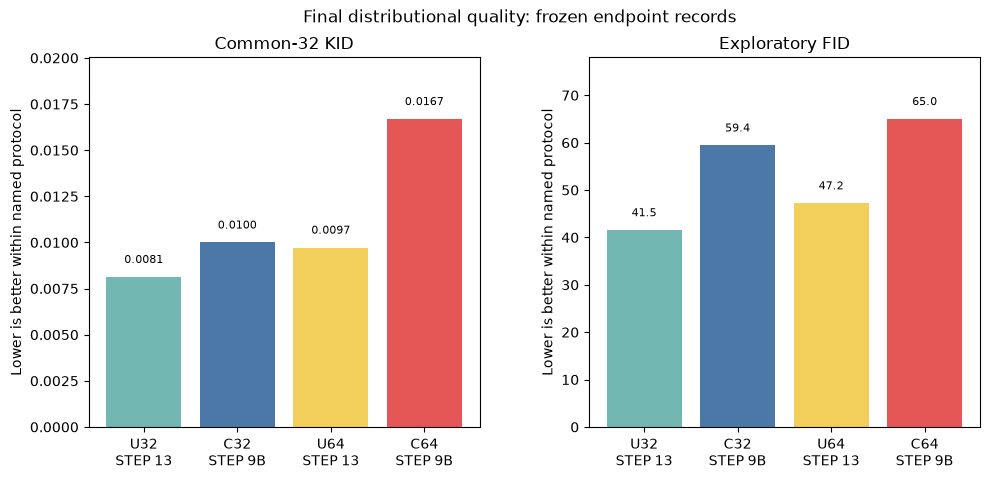

In [22]:
# Final layout export for Figure B: preserve a dedicated provenance margin.
fig,ax=plt.subplots(1,2,figsize=(11.5,4.8),gridspec_kw={'wspace':.28}); labels=['U32\nSTEP 13','C32\nSTEP 9B','U64\nSTEP 13','C64\nSTEP 9B']
for a,i,title,fmt in [(ax[0],1,'Common-32 KID','.4f'),(ax[1],2,'Exploratory FID','.1f')]:
 vals=[r[i] for r in rows]; bars=a.bar(labels,vals,color=[r[3] for r in rows]); a.set(title=title,ylabel='Lower is better within named protocol', ylim=(0,max(vals)*1.20)); a.tick_params(axis='x',rotation=0)
 for q,v in zip(bars,vals): a.text(q.get_x()+q.get_width()/2,v+max(vals)*.045,format(v,fmt),ha='center',fontsize=8)
fig.suptitle('Final distributional quality: frozen endpoint records'); fig.tight_layout(rect=(0,0,1,.90))
for e in ('png','pdf'): fig.savefig(FIGURE_DIR/f'final_distributional_quality.{e}',dpi=300,bbox_inches='tight')
plt.show()

## 5. Qualitative gallery of the four released checkpoints

The two panels below load authenticated saved PNGs rather than invoking inference. Unconditional samples are shown only by model and seed: they do not answer a caption. Conditional rows use the same canonical OOD caption and nominal seed for C32/C64. The images are illustrative, not a ranking or a quantitative measurement.

In [ ]:
from PIL import Image
from IPython.display import display, Markdown

GALLERY_ROOT = ROOT / 'results' / 'qualitative' / 'final_four_model_gallery_seed2026'
GALLERY_MANIFEST = GALLERY_ROOT / 'provenance_manifest.json'
assert GALLERY_MANIFEST.is_file(), f'Missing final-gallery provenance: {GALLERY_MANIFEST}'
gallery = json.loads(GALLERY_MANIFEST.read_text(encoding='utf-8'))
assert gallery['sampler'] == 'ancestral_ddpm_1000_steps' and gallery['checkpoint_weight_variant'] == 'EMA'
for item in gallery['unconditional'] + gallery['conditional']:
    image_path = ROOT / item['png']
    assert image_path.is_file() and hashlib.sha256(image_path.read_bytes()).hexdigest() == item['png_sha256']
    assert public[item['model']]['sha256'] == item['checkpoint_sha256']

def gallery_figure(records, row_keys, column_models, title, filename, row_label):
    fig, axes = plt.subplots(len(row_keys), len(column_models), figsize=(8.5, 6.7), squeeze=False, gridspec_kw={'wspace': .04, 'hspace': .10})
    lookup = {(record[row_label], record['model']): record for record in records}
    for r, key in enumerate(row_keys):
        for c, model_id in enumerate(column_models):
            record = lookup[(key, model_id)]
            axes[r, c].imshow(Image.open(ROOT / record['png']))
            axes[r, c].axis('off')
            if r == 0: axes[r, c].set_title(model_id, fontsize=12, fontweight='bold', pad=7)
        axes[r, 0].text(-.10, .5, str(key), transform=axes[r, 0].transAxes, ha='right', va='center', fontsize=11, fontweight='bold')
    fig.suptitle(title, fontsize=14)
    fig.tight_layout(rect=(.04, 0, 1, .94))
    for extension in ('png', 'pdf'): fig.savefig(FIGURE_DIR / f'{filename}.{extension}', dpi=300, bbox_inches='tight')
    return fig

unconditional_gallery = gallery_figure(gallery['unconditional'], [2026, 2027], ['DDPM-U32', 'DDPM-U64'], 'Unconditional qualitative samples — no requested caption', 'final_four_model_unconditional_gallery', 'seed')
conditional_gallery = gallery_figure(gallery['conditional'], ['OOD1', 'OOD2'], ['DDPM-C32', 'DDPM-C64'], 'Conditional compositional OOD samples — shared caption and nominal seed 2026 per row', 'final_four_model_conditional_gallery', 'ood')
display(unconditional_gallery); display(conditional_gallery)
caption_lines = '\n'.join(f"- **{key}** — `{next(r['caption'] for r in gallery['conditional'] if r['ood'] == key)}`" for key in ('OOD1', 'OOD2'))
display(Markdown('**Conditional caption provenance**\n' + caption_lines + '\n\nAll eight PNG and checkpoint SHA-256 values are verified against the manifest above.'))
plt.close(unconditional_gallery); plt.close(conditional_gallery)

In [ ]:
RUN_GALLERY_REGENERATION = False
if RUN_GALLERY_REGENERATION:
    raise RuntimeError('Gallery regeneration is intentionally disabled; use the public CLI with the manifest seeds and controls to create a new provenance-recorded gallery.')
print('Gallery regeneration disabled; saved authenticated PNGs were displayed.')